# Segmentation RFM & clustering
RFM puis KMeans → personas et recommandations (voir docs/marketing.md).

In [1]:
import sys

sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from shoppulse.features.rfm import compute_rfm
from shoppulse.features.segmentation import FEATURES, cluster_rfm

In [2]:
rfm = compute_rfm()
print(len(rfm), "clients")
rfm.head()

94983 clients


,customer_unique_id,recence,frequence,montant,R,F,M,rfm_score,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,129.90,4,1,4,9,Clients fidèles
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,18.90,4,1,1,6,Nouveaux / prometteurs
2,0000f46a3911fa3c0805444483337064,585,1,69.00,1,1,2,4,Perdus / dormants
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,25.99,2,1,1,4,Perdus / dormants
4,0004aac84e0df4da2b147fca70cf8255,336,1,180.00,2,1,5,8,Perdus / dormants


## Répartition des segments RFM

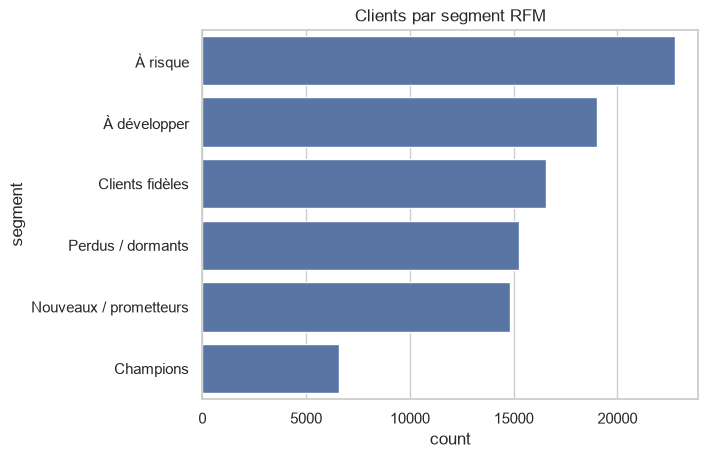

In [3]:
ax = sns.countplot(y="segment", data=rfm, order=rfm["segment"].value_counts().index)
ax.set_title("Clients par segment RFM")
plt.show()

## Choix de k — méthode du coude

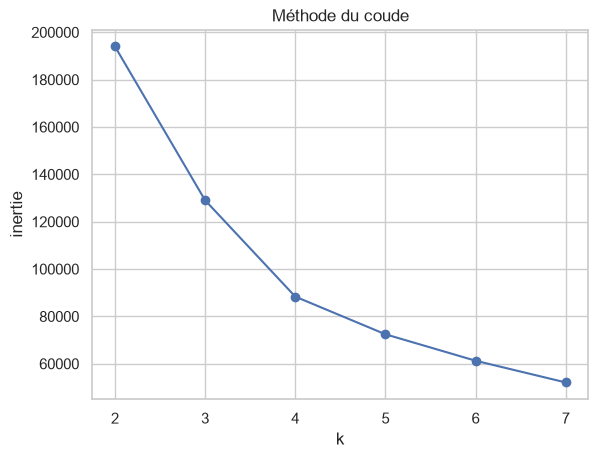

In [4]:
x = rfm[FEATURES].astype(float).copy()
x["frequence"] = np.log1p(x["frequence"])
x["montant"] = np.log1p(x["montant"])
xs = StandardScaler().fit_transform(x)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(xs).inertia_ for k in range(2, 8)]
plt.plot(range(2, 8), inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertie")
plt.title("Méthode du coude")
plt.show()

## Clustering k=4 et profils

In [5]:
data, profiles = cluster_rfm(rfm, k=4)
profiles

,cluster,taille,recence_moy,frequence_moy,montant_moy,rfm_score_moy,part_pct
0,2,2887,270.08,2.11,259.95,12.28,3.04
1,1,33240,211.65,1.00,251.36,10.82,35.00
2,0,27491,476.32,1.00,108.92,7.14,28.94
3,3,31365,202.35,1.00,44.46,8.40,33.02


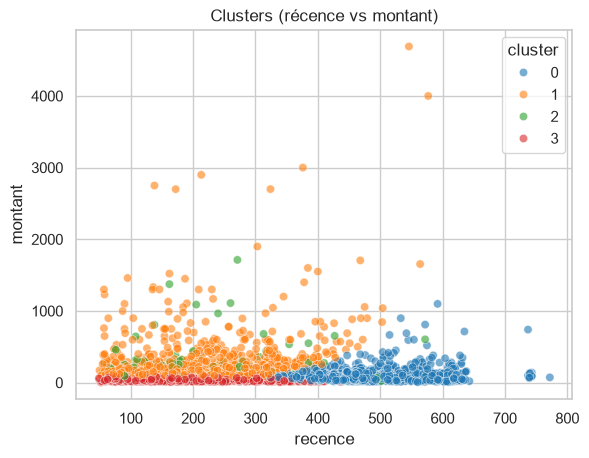

In [6]:
sns.scatterplot(
    data=data.sample(3000, random_state=1),
    x="recence",
    y="montant",
    hue="cluster",
    palette="tab10",
    alpha=0.6,
)
plt.title("Clusters (récence vs montant)")
plt.show()

## Personas
Les profils sont traduits en 3 personas actionnables avec recommandations chiffrées dans **docs/marketing.md** (relance cross-sell, win-back, fidélité VIP).